# 大数据招聘岗位数据分析 —— 数据清洗与 EDA

**数据集**：猎聘公开招聘页面抓取快照，2019-12，搜索关键词「数据分析」，全国 · **4,002 行 × 15 列**

**分析目标**：回答三个问题——数据分析类岗位**要什么人、给多少钱、门槛在哪**，为求职定位提供依据。

**流程**：数据概览 → 清洗（去重 / 缺失 / 类型转换 / 异常）→ 描述统计 → 分组统计 → 交叉分析 → 结论

---
### 四条核心原则

| 原则 | 做法 | 原因 |
|---|---|---|
| 原始表只读 | 清洗全程在 `df` 副本上做，`df_raw` 永不修改 | 保证可回溯、可复算 |
| 缺失不填充 | 标「未知」并作为独立类别参与统计 | 招聘数据的缺失是结构性缺失，填均值/众数等于伪造信息 |
| 异常不删除 | 打标记，从对应统计中剔除，行数保留 | 极端高薪是真实岗位，删掉会低估市场 |
| 口径显式 | 每个结论都标注样本量 n | 不给基数的百分比没有可信度 |

## 一、环境准备与数据载入

In [1]:
import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt

# ---- 中文显示（Windows）----
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.unicode.east_asian_width', True)

# 相对路径：请在 src/ 目录下启动 Jupyter 运行本笔记本
DATA_PATH = '../data/猎聘招聘_数据分析岗_原始.csv'

# utf-8-sig：带 BOM 的 CSV 必须用这个编码，否则第一列列名会带上不可见字符
df_raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')

# 铁律①：原始表只读，所有清洗在副本上做
df = df_raw.copy()

print('原始数据形状：', df.shape)
df.head(3)

原始数据形状： (4002, 15)


,发布日期,岗位名称,薪酬low,薪酬high,几薪,工作城市,城市2,城市3,地区,学历,工作年限,公司名称,公司行业,其他方面,链接
0,2019年12月15日,招聘数据统计,6,8.0,12.0,北京,NaN,NaN,NaN,大专及以上,1年以上,一指遥(北京)科技发展有限公司常营分公司,批发零售,带薪年假|节日礼物|管理规范|技能培训|岗位晋升|团队聚餐|发展空间大|五险...,https://www.liepin.com/job/1925149377.shtml
1,2019年12月15日,招聘数据分析岗（商业总部）,13,26.0,12.0,深圳,NaN,NaN,NaN,本科及以上,3年以上,房产开发,房产开发,绩效奖金|带薪年假|午餐补助|定期体检|节日礼物|管理规范|技能培训|五险一金|上市公司...,https://www.liepin.com/job/1925004989.shtml
2,2019年12月15日,招聘资深数据分析师,9,14.0,14.0,上海,NaN,NaN,静安区,本科及以上,3年以上,贝塔斯曼,专业服务,年底双薪|带薪年假|定期体检|年度旅游|节日礼物|五险一金|发展空间大...,https://www.liepin.com/job/1925072231.shtml


## 二、先看清数据，再动手

清洗前必须回答三个问题：**多少行、每列什么类型、缺失分布在哪**。
直接 `df.dropna()` 或 `df.fillna(0)` 是最常见的错误起点——不知道缺什么就开始处理，等于制造新问题。

In [2]:
# 一张表看清字段结构：类型 / 缺失 / 唯一值 / 样例
overview = pd.DataFrame({
    '数据类型': df.dtypes.astype(str),
    '非空数': df.notna().sum(),
    '缺失数': df.isna().sum(),
    '缺失率%': (df.isna().mean() * 100).round(2),
    '唯一值数': df.nunique(),
    '样例': [df[c].dropna().iloc[0] if df[c].notna().any() else '' for c in df.columns],
})
overview

,数据类型,非空数,缺失数,缺失率%,唯一值数,样例
发布日期,object,4002,0,0.00,18,2019年12月15日
岗位名称,object,4002,0,0.00,1700,招聘数据统计
薪酬low,object,4002,0,0.00,50,6
薪酬high,float64,3353,649,16.22,71,8.0
几薪,float64,3356,646,16.14,13,12.0
工作城市,object,3402,600,14.99,90,北京
城市2,object,149,3853,96.28,26,北京
城市3,object,75,3927,98.13,16,浙江
地区,object,1395,2607,65.14,349,静安区
学历,object,4002,0,0.00,7,大专及以上


**这张表已经暴露了三个必须先处理的问题：**

1. `城市2` / `城市3` / `地区` 缺失率极高 —— 这不是数据坏了，而是**结构性缺失**：直辖市没有"城市2"，
   只有部分岗位填了商圈。这类缺失**绝不能填充**，硬填会把"没填"变成"填了某个值"。
2. `薪酬low` / `薪酬high` 里混着文本「面议」—— 列是 object 类型，**不能直接算平均**，必须先转数值。
3. `发布日期` 是中文格式「2019年12月15日」—— 要转成 datetime 才能做时间维度分析。

In [3]:
# 数值列先看一眼，判断量纲与可疑值
df.describe().T

,count,mean,std,min,25%,50%,75%,max
薪酬high,3353.0,27.063823,18.056629,2.0,15.0,24.0,35.0,170.0
几薪,3356.0,13.088796,2.223807,12.0,12.0,12.0,14.0,100.0


`薪酬low` 的 max = 170、`几薪` 的 max = 100 ——
单位分别是「千元/月」和「发薪月数」，`几薪=100` 就是一年发 100 个月工资，明显是录入错误。
这类要靠**业务规则**而不是统计方法识别。

## 三、去重

招聘数据有三类重复，要分开处理：

| 类型 | 判定依据 | 处理 |
|---|---|---|
| 完全重复 | 所有列都相同 | 直接删（抓取重跑导致） |
| 业务主键重复 | 详情链接 `链接`（平台侧唯一标识一个岗位） | 保留信息最完整的一条 |
| 同公司同岗位重复发布 | 公司+岗位名+城市相同 | **不删**，这是真实的多次发布行为 |

> ⚠️ 为什么用「链接」而不是「公司+岗位名」：同名岗位在不同城市是两个岗位，按名字去重会误删真实数据。

In [4]:
n0 = len(df)

# ① 完全重复行
df = df.drop_duplicates()
n1 = len(df)

# ② 业务主键去重：同一链接只保留「非空字段最多」的一条
df['_完整度'] = df.notna().sum(axis=1)
df = (df.sort_values('_完整度', ascending=False)
        .drop_duplicates(subset=['链接'], keep='first')
        .drop(columns='_完整度')
        .sort_index())
n2 = len(df)

print(f'完全重复删除：{n0 - n1} 行')
print(f'链接重复删除：{n1 - n2} 行')
print(f'去重后剩余：{n2} 行（删除率 {(n0 - n2) / n0 * 100:.2f}%）')

完全重复删除：16 行
链接重复删除：2 行
去重后剩余：3984 行（删除率 0.45%）


## 四、缺失值处理

**原则：能归因的归因，不能归因的显式标「未知」，绝不填充。**

招聘数据的缺失几乎都不是随机缺失，而是携带业务含义：

- `城市2`/`地区` 缺失 → 直辖市或未填商圈，属于**结构性缺失**
- `工作城市` 缺失 → 猎头保密岗、公司被脱敏的岗位，**缺失本身就是信息**
- `薪酬=面议` → 平台侧未公开，是「未公开」而不是「没有」
- `几薪` 缺失 → 只在薪资公开时才可能存在，是前者的连带缺失

In [5]:
# ① 工作城市：标「未知」作为独立类别（不填充众数）
df['城市'] = df['工作城市'].fillna('未知').str.strip().replace('', '未知')

# ② 城市2/3/地区：结构性缺失，合并成一个「区域」字段
df['区域'] = (df['城市2'].fillna('') + df['城市3'].fillna('') + df['地区'].fillna('')).str.strip()
df['区域'] = df['区域'].replace('', '未知')

# ③ 薪酬口径：「面议」单独标记，后续排除在薪资统计外
df['薪酬口径'] = np.where(df['薪酬low'].astype(str).str.contains('面议'), '面议', '公开')

# ④ 其余分类字段：空值标「未知」，保证仍可参与分组统计
for col in ['学历', '工作年限', '公司行业', '公司名称']:
    df[col] = df[col].fillna('未知').astype(str).str.strip().replace('', '未知')

print('清洗后缺失复核：')
print(df[['城市', '区域', '薪酬口径', '学历', '工作年限', '公司行业']].isna().sum().to_string())
print()
print('城市分布（前 3）：')
print(df['城市'].value_counts().head(3).to_string())

清洗后缺失复核：
城市        0
区域        0
薪酬口径    0
学历        0
工作年限    0
公司行业    0

城市分布（前 3）：
城市
上海    913
北京    634
未知    598


## 五、字段类型转换

这是整份清洗里**信息增益最大**的一步。原始表把薪资存成「6 / 8 / 12」三个数字，
业务含义是「月薪 6k–8k，一年发 12 个月」。不转换，就算不出任何薪资指标。

| 原字段 | 转换后 | 业务含义 |
|---|---|---|
| `薪酬low` / `薪酬high` | `月薪下限` / `月薪上限`（元） | × 1000，单位从千元变元 |
| 上两列 | `月薪中位` | 区间中点，作为单值代表 |
| `几薪` | `几薪_填补` | 年薪 = 月薪 × 几薪，13/14 薪很常见 |
| `发布日期`（中文） | `发布日期_dt` + `星期` | 支持时间维度分析 |
| `学历` | `学历_规范`（有序类别）+ `学历层级`（数值） | 支持排序与相关分析 |
| `工作年限` | `经验年限下限` + `经验档位` | 从「3年以上」提取出数字 3 |

In [6]:
# ---- 5.1 薪资：文本 → 数值 ----
# errors='coerce'：把「面议」这类无法转换的值变成 NaN，而不是报错中断
for c in ['薪酬low', '薪酬high']:
    df[c + '_num'] = pd.to_numeric(df[c], errors='coerce')

df['几薪_num'] = pd.to_numeric(df['几薪'], errors='coerce')

# 单位：千元/月 → 元/月
df['月薪下限'] = (df['薪酬low_num'] * 1000).round(0)
df['月薪上限'] = (df['薪酬high_num'] * 1000).round(0)
df['月薪中位'] = ((df['月薪下限'] + df['月薪上限']) / 2).round(0)

# 几薪缺失按 12 补齐，但要留痕（后面用它算质量标记）
df['几薪_缺失'] = df['几薪_num'].isna()
df['几薪_填补'] = df['几薪_num'].fillna(12)
df['年薪'] = (df['月薪中位'] * df['几薪_填补']).round(0)

df[['薪酬low', '薪酬high', '几薪', '月薪下限', '月薪上限', '月薪中位', '年薪']].head()

,薪酬low,薪酬high,几薪,月薪下限,月薪上限,月薪中位,年薪
0,6,8.0,12.0,6000.0,8000.0,7000.0,84000.0
1,13,26.0,12.0,13000.0,26000.0,19500.0,234000.0
2,9,14.0,14.0,9000.0,14000.0,11500.0,161000.0
3,10,15.0,14.0,10000.0,15000.0,12500.0,175000.0
4,12,30.0,12.0,12000.0,30000.0,21000.0,252000.0


In [7]:
# ---- 5.2 日期：中文格式 → datetime ----
date_str = (df['发布日期']
            .str.replace('年', '-', regex=False)
            .str.replace('月', '-', regex=False)
            .str.replace('日', '', regex=False))
df['发布日期_dt'] = pd.to_datetime(date_str, errors='coerce')
df['星期'] = df['发布日期_dt'].dt.dayofweek.map(
    {0: '周一', 1: '周二', 2: '周三', 3: '周四', 4: '周五', 5: '周六', 6: '周日'})
df['发布日'] = df['发布日期_dt'].dt.date

print('日期转换失败：', df['发布日期_dt'].isna().sum(), '行')
print('发布日期范围：', df['发布日期_dt'].min().date(), '~', df['发布日期_dt'].max().date())

日期转换失败： 0 行
发布日期范围： 2019-12-03 ~ 2019-12-20


In [8]:
# ---- 5.3 学历：归一化 + 有序类别 ----
# 原始取值很碎：「本科及以上」「统招本科」「学历不限」「中专/中技及以上」
EDU_MAP = {'学历不限': '不限', '不限': '不限',
           '中专': '中专/中技', '中技': '中专/中技',
           '大专': '大专', '专科': '大专',
           '统招本科': '本科', '本科': '本科',
           '硕士': '硕士', '研究生': '硕士',
           '博士': '博士'}
EDU_ORDER = ['不限', '中专/中技', '大专', '本科', '硕士', '博士', '未知']
EDU_LEVEL = {'不限': 0, '中专/中技': 3, '大专': 4, '本科': 5, '硕士': 6, '博士': 7, '未知': np.nan}


def norm_edu(x):
    x = str(x)
    for k, v in EDU_MAP.items():
        if k in x:
            return v
    return '未知'


df['学历_规范'] = df['学历'].map(norm_edu)
df['学历层级'] = df['学历_规范'].map(EDU_LEVEL)                     # 数值版，便于算相关
df['是否统招'] = df['学历'].astype(str).str.contains('统招').map({True: '是', False: '否'})
# 有序类别：排序时按学历高低，而不是按拼音
df['学历_规范'] = pd.Categorical(df['学历_规范'], categories=EDU_ORDER, ordered=True)

print(df['学历_规范'].value_counts().sort_index().to_string())

学历_规范
不限          249
中专/中技       6
大专          387
本科         3123
硕士          209
博士           10
未知            0


In [9]:
# ---- 5.4 工作经验：「3年以上」→ 数字 3 ----
def parse_exp(x):
    '''返回 (年限下限, 经验档位)。「经验不限」记为 0 年。'''
    s = str(x)
    if '不限' in s or '无经验' in s:
        return 0, '不限'
    m = re.search(r'(\d+(?:\.\d+)?)', s)
    if not m:
        return np.nan, '未知'
    y = float(m.group(1))
    band = '1年以内' if y <= 1 else '1-3年' if y <= 3 else '3-5年' if y <= 5 else '5年以上'
    return y, band


df[['经验年限下限', '经验档位']] = df['工作年限'].apply(lambda x: pd.Series(parse_exp(x)))

# 交叉验证：原始文本与解析结果必须一一对应，否则说明正则漏了某种写法
pd.crosstab(df['工作年限'], df['经验档位'])

经验档位,1-3年,1年以内,3-5年,5年以上,不限
工作年限,,,,,
10年以上,0,0,0,15,0
12年以上,0,0,0,1,0
1年以上,0,553,0,0,0
2年以上,654,0,0,0,0
3年以上,1332,0,0,0,0
4年以上,0,0,125,0,0
5年以上,0,0,758,0,0
6年以上,0,0,0,31,0
7年以上,0,0,0,26,0


In [10]:
# ---- 5.5 岗位名称、岗位方向、职级 ----
# 岗位名全部带「招聘」前缀（抓的是搜索页标题），必须先去掉才能真正按岗位名统计
df['岗位名称_清洗'] = df['岗位名称'].str.replace(r'^招聘', '', regex=True).str.strip()

# 岗位方向：关键词归类，顺序敏感（先命中先生效，「大数据」要排在「数据分析」前）
DIRECTION = [
    ('数据开发/数仓', ['大数据开发', '数据开发', '数据仓库', '数仓', 'etl', 'hadoop', 'spark', 'hive']),
    ('算法/挖掘',     ['算法', '数据挖掘', '机器学习', '建模', '推荐', 'nlp']),
    ('BI/报表',       ['bi', '报表', '可视化']),
    ('大数据分析',     ['大数据']),
    ('数据统计',       ['统计']),
    ('数据分析',       ['数据分析', '商业分析', '业务分析', '经营分析', '风控', '增长']),
]


def direction_of(t):
    t = str(t).lower()
    for name, kws in DIRECTION:
        if any(k in t for k in kws):
            return name
    return '其他'


df['岗位方向'] = df['岗位名称_清洗'].map(direction_of)

# 职级：抽管理/资历词，用于后面做「同职级对比」
LEVEL = ['总监', '经理', '主管', '专家', '资深', '高级', '专员', '助理']
df['职级'] = df['岗位名称_清洗'].apply(lambda t: next((l for l in LEVEL if l in t), '无'))

# 福利标签数：'带薪年假|五险一金|...' → 计个数
df['福利标签数'] = df['其他方面'].fillna('').apply(lambda s: len([x for x in str(s).split('|') if x.strip()]))

print('岗位方向分布：')
print(df['岗位方向'].value_counts().to_string())
print()
print('职级分布：')
print(df['职级'].value_counts().to_string())

岗位方向分布：
岗位方向
数据分析         3569
大数据分析        172
数据统计           82
BI/报表            81
算法/挖掘          65
数据开发/数仓       9
其他                6

职级分布：
职级
无      2495
经理     355
高级     329
专家     281
专员     191
资深     132
主管     106
总监      67
助理      28


### 5.6 还有一个隐蔽的字段污染：行业列混入了融资阶段

`公司行业` 的 TOP 取值里出现了「轮」「未融资」「上市」「战略投资」——
它们是**融资阶段**，被爬虫合并进了行业字段。不拆开的话，"哪个行业招人最多"会算成"哪个融资阶段招人最多"。

In [11]:
# 融资阶段词表
FIN_STAGES = ['不需要融资', '未融资', '天使轮', '种子轮', 'pre-a轮', 'a+轮', 'a轮', 'b轮',
              'c轮', 'd轮', 'e轮', '已上市', '上市', '战略投资', '融资']
# 特例：整格只有「轮」时（爬虫把「A轮」的字母截掉了），单独处理，
# 不能直接把「轮」加进上面的词表——否则「汽车轮胎」这类行业名会被误判
FIN_BARE = {'轮', '融资轮次'}


def split_industry(x):
    '''返回 (行业, 融资阶段)。行业里若只剩融资词，则行业记为「未知」。'''
    t = str(x).strip()
    if not t or t == '未知':
        return '未知', '未知'
    if t in FIN_BARE:
        return '未知', '融资轮次(原文缺字母)'
    low = t.lower()
    stage = next((s for s in FIN_STAGES if s in low), '未知')
    if stage == '未知':
        return t, '未知'
    rest = low
    for s in FIN_STAGES:                       # 剥掉融资词，剩下的才是行业
        rest = rest.replace(s, '')
    rest = rest.strip(' |/-')
    industry = t if len(rest) >= 2 else '未知'
    return industry, stage


df[['行业_清洗', '融资阶段']] = df['公司行业'].apply(lambda x: pd.Series(split_industry(x)))

print('拆分前后对比：')
print('  原「公司行业」唯一值数：', df['公司行业'].nunique())
print('  清洗后「行业_清洗」唯一值数：', df['行业_清洗'].nunique())
print('  识别出融资阶段的行数：', (df['融资阶段'] != '未知').sum())
print('  其中行业信息同时丢失的行数：', ((df['融资阶段'] != '未知') & (df['行业_清洗'] == '未知')).sum())
print()
print('融资阶段分布：')
print(df['融资阶段'].value_counts().head(6).to_string())

拆分前后对比：
  原「公司行业」唯一值数： 462
  清洗后「行业_清洗」唯一值数： 457
  识别出融资阶段的行数： 728
  其中行业信息同时丢失的行数： 727

融资阶段分布：
融资阶段
未知                    3256
融资轮次(原文缺字母)     421
未融资                   131
上市                     101
战略投资                  58
天使轮                    16


## 六、异常值处理

异常值分三类，处理方式完全不同：

| 类型 | 判定方法 | 处理 |
|---|---|---|
| **统计异常** | IQR 法：超出 `[Q1-1.5IQR, Q3+1.5IQR]` | **标记但保留**，只做敏感性对照 |
| **业务异常** | 月薪 < 1000 元；几薪 > 24 | 标记，并从薪资统计中剔除 |
| **逻辑异常** | 薪资下限 > 上限；公司名 = 行业词（爬虫列错位）；城市填了省份 | 标记，相关分析中排除 |

> ⚠️ 为什么不删统计异常：月薪 8 万的数据分析专家是**真实岗位**，删掉会让市场薪资被系统性低估。
> 正确做法是保留在样本里，用「中位数 + 截尾均值」两个口径对照，并在报告里说明。

In [12]:
# ---- 6.1 统计异常（IQR 法）----
s_raw = df['月薪中位'].dropna()
q1, q3 = s_raw.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df['异常_统计'] = (df['月薪中位'] < lower) | (df['月薪中位'] > upper)

print(f'Q1 = {q1:,.0f}    Q3 = {q3:,.0f}    IQR = {iqr:,.0f}')
print(f'IQR 栅栏：{lower:,.0f} ~ {upper:,.0f}')
print(f'统计异常：{df["异常_统计"].sum()} 行（占有效薪资样本 {df["异常_统计"].sum()/len(s_raw)*100:.1f}%）')

Q1 = 11,500    Q3 = 30,000    IQR = 18,500
IQR 栅栏：-16,250 ~ 57,750
统计异常：68 行（占有效薪资样本 2.0%）


In [13]:
# 极端值必须人工看一眼：是真实高薪岗，还是「年薪被填成月薪」的录入错误？
df.nlargest(8, '月薪中位')[
    ['岗位名称_清洗', '月薪下限', '月薪上限', '城市', '学历_规范', '经验档位']
]

,岗位名称_清洗,月薪下限,月薪上限,城市,学历_规范,经验档位
3222,数据分析产品经理,150000.0,170000.0,深圳,本科,3-5年
907,Python数据分析（量化金融）课程老师,120000.0,150000.0,南京,硕士,不限
908,Python数据分析（量化金融）课程老师,120000.0,150000.0,常州,硕士,不限
3640,商业数据分析专家,115000.0,154000.0,未知,不限,1-3年
2935,数据分析总监,100000.0,150000.0,广州,硕士,5年以上
250,数据分析专家（IOT方向）,100000.0,130000.0,上海,本科,5年以上
251,数据分析专家（IOT方向）,100000.0,130000.0,深圳,本科,5年以上
260,数据分析专家（IOT方向）,100000.0,130000.0,杭州,本科,5年以上


看这个清单就能判断：**「数据分析专家/负责人」开到 100–130k 月薪可能是真的**（年薪百万级的技术专家），
而**「Python数据分析课程老师」120–150k 明显是把年薪填成了月薪**。

所以处理上不做一刀切删除，而是：
- 标记为统计异常，**保留在样本中**（避免误删真实高薪岗）
- 在描述统计里同时给出**中位数**和**5% 截尾均值**两个口径
- 报告中对极端值只做敏感性说明

In [14]:
# ---- 6.2 业务异常 ----
df['异常_低薪'] = df['月薪中位'].notna() & (df['月薪中位'] < 1000)   # 日薪/时薪被误当月薪
df['异常_几薪'] = df['几薪_填补'] > 24                              # 一年发超过 24 个月工资

# ---- 6.3 逻辑异常 ----
df['异常_倒挂'] = df['月薪下限'] > df['月薪上限']

# 公司名被写成行业词（爬虫解析时列错位，如 公司名称='互联网/移动互联网/电子商务'）
industry_words = set(df['公司行业'].astype(str).unique())
df['异常_公司名'] = df['公司名称'].isin(industry_words)

# 城市填成了省份（如「广东」「山东」），省级数据无法用于城市对比
PROVINCE_ONLY = ['河北', '山西', '辽宁', '吉林', '黑龙江', '江苏', '浙江', '安徽', '福建',
                 '江西', '山东', '河南', '湖北', '湖南', '广东', '广西', '海南', '四川',
                 '贵州', '云南', '西藏', '陕西', '甘肃', '青海', '宁夏', '新疆', '内蒙古']
df['异常_城市'] = df['城市'].isin(PROVINCE_ONLY)

print('异常标记统计：')
for c in ['异常_统计', '异常_低薪', '异常_几薪', '异常_倒挂', '异常_公司名', '异常_城市']:
    print(f'  {c:<10} {df[c].sum():>5} 行')

异常标记统计：
  异常_统计         68 行
  异常_低薪          0 行
  异常_几薪          2 行
  异常_倒挂          0 行
  异常_公司名       664 行
  异常_城市         32 行


In [15]:
# ---- 6.4 生成「薪资分析可用」阀门 ----
# 只有同时满足：薪资已公开 + 非低薪 + 几薪合理 + 无倒挂，才进入薪资统计
df['薪资分析可用'] = (df['月薪中位'].notna()
                 & ~df['异常_低薪']
                 & ~df['异常_几薪']
                 & ~df['异常_倒挂'])

n_all, n_sal = len(df), int(df['薪资分析可用'].sum())
print(f'总行数 {n_all}')
print(f'进入薪资统计 {n_sal} 行（{n_sal / n_all * 100:.1f}%）')
print(f'被排除 {n_all - n_sal} 行：')
print(f'  薪资面议/缺失  {int(df["月薪中位"].isna().sum())} 行')
print(f'  低薪异常       {int(df["异常_低薪"].sum())} 行')
print(f'  几薪异常       {int(df["异常_几薪"].sum())} 行')

总行数 3984
进入薪资统计 3334 行（83.7%）
被排除 650 行：
  薪资面议/缺失  648 行
  低薪异常       0 行
  几薪异常       2 行


## 七、清洗结果汇总与导出

清洗的终点不是"数据变干净了"，而是**每一处改动都能说清楚**。下面把清洗前后并排对照。

In [16]:
compare = pd.DataFrame({
    '指标': ['行数', '薪资可统计行数', '薪资可统计占比%', '城市缺失/未知行数',
             '公司名异常行数', '行业已拆分融资阶段行数'],
    '清洗前': [
        len(df_raw),
        int(pd.to_numeric(df_raw['薪酬low'], errors='coerce').notna().sum()),
        round(pd.to_numeric(df_raw['薪酬low'], errors='coerce').notna().mean() * 100, 1),
        int(df_raw['工作城市'].isna().sum()),
        0, 0,
    ],
    '清洗后': [
        len(df),
        int(df['薪资分析可用'].sum()),
        round(df['薪资分析可用'].mean() * 100, 1),
        int((df['城市'] == '未知').sum()),
        int(df['异常_公司名'].sum()),
        int((df['融资阶段'] != '未知').sum()),
    ],
})
compare['清洗前'] = compare['清洗前'].map(lambda x: f'{x:,}')
compare['清洗后'] = compare['清洗后'].map(lambda x: f'{x:,}')
compare

,指标,清洗前,清洗后
0,行数,"4,002.0","3,984.0"
1,薪资可统计行数,"3,356.0","3,334.0"
2,薪资可统计占比%,83.9,83.7
3,城市缺失/未知行数,600.0,598.0
4,公司名异常行数,0.0,664.0
5,行业已拆分融资阶段行数,0.0,728.0


In [17]:
# ---- 7.1 落盘（与原笔记本同目录，UTF-8-BOM 便于 Excel 直接打开）----
OUT_COLS = ['岗位名称_清洗', '岗位方向', '职级', '月薪下限', '月薪上限', '月薪中位', '几薪_填补',
            '年薪', '薪酬口径', '学历_规范', '学历层级', '是否统招', '工作年限', '经验档位',
            '经验年限下限', '城市', '区域', '公司名称', '行业_清洗', '融资阶段', '福利标签数',
            '发布日期_dt', '星期', '薪资分析可用', '链接']
df_out = df[OUT_COLS].copy()

out_path = '../data/数据分析岗_清洗后.csv'
df_out.to_csv(out_path, index=False, encoding='utf-8-sig')
print(f'已导出 {out_path}，形状 {df_out.shape}')

已导出 ../data/数据分析岗_清洗后.csv，形状 (3984, 25)


---
# 探索性分析（EDA）

## 八、分析维度地图

EDA 不是把所有图都画一遍，而是**按业务问题组织维度**。本项目分四个层次：

| 层次 | 维度 | 回答的业务问题 |
|---|---|---|
| ① 描述统计 | 集中趋势、离散度、偏态 | 这个岗位整体给多少钱？分布集中还是两极？ |
| ② 单维分组 | 学历 / 经验 / 城市 / 方向 / 职级 | 哪个因素对薪资影响最大？ |
| ③ 多维交叉 | 方向×经验、控制变量后的学历差异 | 上一层的结论是不是被其他因素带偏了？ |
| ④ 时间与结构 | 发布趋势、周末效应、行业集中度 | 数据本身可信吗？市场结构长什么样？ |

## 九、描述统计：薪资到底长什么样

**业务含义**：招聘薪资通常右偏，均值会被少数高薪岗拉高，中位数才代表"典型岗位"的报价。
P25/P75 说明"大部分岗位落在什么区间"——求职谈薪看的是这个区间，不是平均值。

In [18]:
s = df.loc[df['薪资分析可用'], '月薪中位']

stats = pd.Series({
    '样本量 n': len(s),
    '均值': s.mean(),
    '中位数 P50': s.median(),
    'P10': s.quantile(0.10),
    'P25': s.quantile(0.25),
    'P75': s.quantile(0.75),
    'P90': s.quantile(0.90),
    '标准差': s.std(),
    '变异系数 CV': s.std() / s.mean(),
    '偏度 skew': s.skew(),
    '峰度 kurt': s.kurt(),
}).round(2)
stats.to_frame('月薪（元）')

,月薪（元）
样本量 n,3334.00
均值,21797.84
中位数 P50,18500.00
P10,7000.00
P25,11500.00
P75,30000.00
P90,40000.00
标准差,14774.05
变异系数 CV,0.68
偏度 skew,2.18


In [19]:
# 均值 vs 中位数：差距就是右偏的直接证据
print(f'均值 {s.mean():,.0f} vs 中位数 {s.median():,.0f}，均值被高薪岗拉高 {(s.mean()/s.median()-1)*100:.1f}%')
print(f'→ 报告应写「月薪中位数 {s.median():,.0f} 元」，写均值会高估典型水平')

# 5% 截尾均值：剔掉两端各 5% 后重算，作为稳健性对照
trimmed = s[(s >= s.quantile(0.05)) & (s <= s.quantile(0.95))]
print(f'5% 截尾均值 {trimmed.mean():,.0f} 元（与中位数越接近，中位数越可信）')

均值 21,798 vs 中位数 18,500，均值被高薪岗拉高 17.8%


→ 报告应写「月薪中位数 18,500 元」，写均值会高估典型水平
5% 截尾均值 20,606 元（与中位数越接近，中位数越可信）


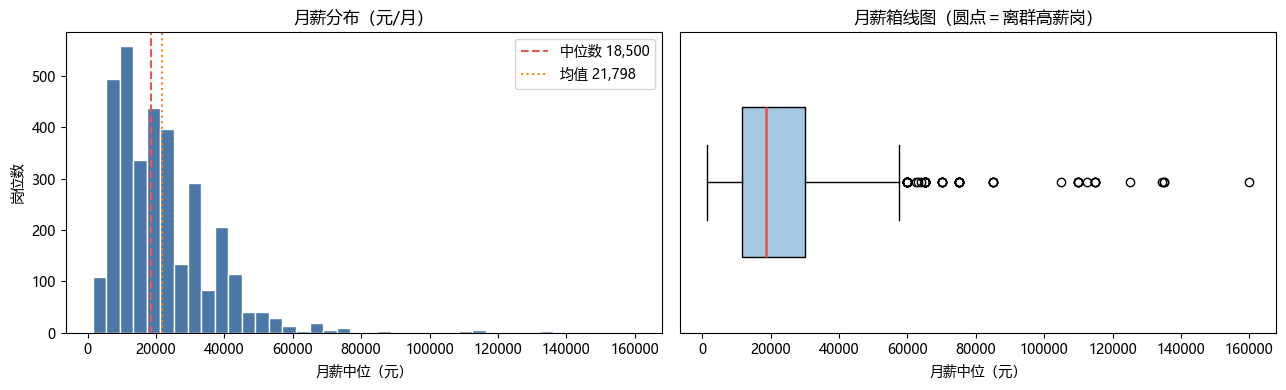

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 左：直方图看形态
axes[0].hist(s, bins=40, color='#4C78A8', edgecolor='white')
axes[0].axvline(s.median(), color='#E45756', linestyle='--', label=f'中位数 {s.median():,.0f}')
axes[0].axvline(s.mean(), color='#F58518', linestyle=':', label=f'均值 {s.mean():,.0f}')
axes[0].set_title('月薪分布（元/月）')
axes[0].set_xlabel('月薪中位（元）')
axes[0].set_ylabel('岗位数')
axes[0].legend()

# 右：箱线图看分位与离群点
axes[1].boxplot(s, vert=False, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor='#A5C8E1'),
                medianprops=dict(color='#E45756', linewidth=2))
axes[1].set_title('月薪箱线图（圆点＝离群高薪岗）')
axes[1].set_xlabel('月薪中位（元）')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

## 十、分组统计：把薪资按维度拆开看

先封装一个可复用的分组函数——**样本量低于阈值的组不参与结论**，
这是避免"用 3 个样本下结论"的护栏，也是报告里最容易被质疑的地方。

In [21]:
def group_salary(data, by, min_n=30):
    '''按维度分组统计薪资。

    参数
    ----
    data  : DataFrame
    by    : 分组字段（传列表可做多维分组）
    min_n : 样本量下限，低于此值标注「不可下结论」

    返回
    ----
    含 样本量 / 占比 / 中位数 / P25 / P75 / 备注 的表，按中位数降序
    '''
    d = data[data['薪资分析可用']]
    g = d.groupby(by, observed=True)['月薪中位']
    out = pd.DataFrame({
        '样本量': g.size(),
        '中位数': g.median().round(0),
        'P25': g.quantile(0.25).round(0),
        'P75': g.quantile(0.75).round(0),
    })
    out['占比%'] = (out['样本量'] / len(data) * 100).round(1)
    out['备注'] = np.where(out['样本量'] < min_n, f'样本<{min_n}，不可下结论', '')
    return out.sort_values('中位数', ascending=False)


def show(title, table):
    print(f'\n=== {title} ===')
    print(table.to_string())


print('分组函数已定义：group_salary(data, by, min_n=30)')

分组函数已定义：group_salary(data, by, min_n=30)


In [22]:
show('按学历分组', group_salary(df, '学历_规范'))


=== 按学历分组 ===
           样本量   中位数      P25      P75  占比%                 备注
学历_规范                                                               
博士            8  24500.0  20750.0  30625.0    0.2  样本<30，不可下结论
不限          187  22500.0  12500.0  30000.0    4.7                     
本科         2601  20000.0  12500.0  30000.0   65.3                     
硕士          166  20000.0  12500.0  30000.0    4.2                     
大专          366   9000.0   6500.0  13500.0    9.2                     
中专/中技       6   6750.0   4375.0   8750.0    0.2  样本<30，不可下结论


**业务含义**：学历是求职者最直接的门槛问题。但要读出两层信息——
① 大专与本科的薪资差距；② **学历「不限」的岗位反而可能更高薪**。
后者不是"学历无用"的证据，而是这类岗位通常靠能力筛人（专家岗、管理岗），学历不设限但职级要求高。

In [23]:
# 验证上面那个反直觉现象：「不限」组里都是什么职级？
(pd.crosstab(df['学历_规范'], df['职级'], normalize='index') * 100).round(1)

职级,专员,专家,主管,助理,总监,无,经理,资深,高级
学历_规范,,,,,,,,,
不限,3.2,16.9,2.0,0.8,1.2,57.8,8.0,3.6,6.4
中专/中技,16.7,0.0,0.0,0.0,0.0,83.3,0.0,0.0,0.0
大专,15.0,1.0,7.0,2.3,1.0,62.5,7.0,0.8,3.4
本科,3.8,7.2,2.4,0.5,1.7,62.7,9.2,3.7,8.8
硕士,2.4,4.8,0.0,1.0,3.3,67.0,10.0,1.4,10.0
博士,0.0,10.0,0.0,0.0,0.0,50.0,0.0,0.0,40.0


In [24]:
show('按经验分组', group_salary(df, '经验档位'))


=== 按经验分组 ===
          样本量   中位数      P25      P75  占比% 备注
经验档位                                               
5年以上      105  40000.0  30000.0  55000.0    2.6     
3-5年        736  30000.0  22500.0  40000.0   18.5     
1-3年       1676  18000.0  12500.0  26500.0   42.1     
1年以内      462  10000.0   7000.0  15000.0   11.6     
不限         355   9000.0   6500.0  13500.0    8.9     


**业务含义**：经验档位是薪资增长曲线。1-3 年 → 3-5 年的涨幅，直接决定"该在第几年跳槽"，
也决定简历项目该强调"独立负责"还是"配合执行"。

In [25]:
# 城市：先过滤掉「未知」和样本量过小的城市——否则会被 n=1 的城市带偏排名
city_tab = group_salary(df, '城市')
city_tab = city_tab[(city_tab['样本量'] >= 30)]
show('按城市分组（样本≥30）', city_tab)


=== 按城市分组（样本≥30） ===
      样本量   中位数      P25      P75  占比% 备注
城市                                               
未知     487  27500.0  17500.0  37500.0   12.2     
北京     516  22500.0  15000.0  32500.0   13.0     
深圳     305  20000.0  12500.0  30000.0    7.7     
杭州     231  20000.0  12500.0  30000.0    5.8     
上海     766  20000.0  12500.0  30000.0   19.2     
成都      77  15000.0   8000.0  18500.0    1.9     
南京      70  13500.0   9250.0  22500.0    1.8     
武汉      75  12500.0   9000.0  18500.0    1.9     
广州     300  12500.0   8875.0  21500.0    7.5     
重庆      36  12000.0   8000.0  17500.0    0.9     
厦门      36  11750.0   8000.0  15625.0    0.9     
苏州      52  11250.0   7000.0  22875.0    1.3     


**业务含义**：城市是最大的一阶变量。注意 `城市='未知'` 这一组——它不是"没有城市"，
而是"平台未展示城市"，多为猎头或保密发布的高薪岗。
**如果直接把这组删掉，会系统性低估高薪岗位**，所以只能标注、不能删除。

In [26]:
show('按岗位方向分组', group_salary(df, '岗位方向'))
show('按职级分组', group_salary(df, '职级'))


=== 按岗位方向分组 ===
               样本量   中位数      P25      P75  占比%                 备注
岗位方向                                                                    
算法/挖掘          54  22500.0  17500.0  29375.0    1.4                     
其他                2  22250.0  19875.0  24625.0    0.1  样本<30，不可下结论
BI/报表            69  21500.0  15000.0  30000.0    1.7                     
大数据分析        138  21250.0  13500.0  30000.0    3.5                     
数据分析         2990  18500.0  11500.0  30000.0   75.1                     
数据开发/数仓       6  15500.0  12125.0  34250.0    0.2  样本<30，不可下结论
数据统计           75   9000.0   5500.0  13250.0    1.9                     

=== 按职级分组 ===
      样本量   中位数      P25      P75  占比%                 备注
职级                                                               
总监      64  42500.0  37500.0  55000.0    1.6                     
专家     223  37500.0  30000.0  45000.0    5.6                     
资深     106  28500.0  20375.0  35000.0    2.7                     
高级     289

**业务含义**：职级代表责任范围。把职级和学历两维对照，才能回答最实际的那个问题：
「我是大专 + 1 年经验，能对标哪个职级、该要多少钱」。

## 十一、多维交叉：修正单维分组带来的误判

这是整个 EDA 里**最能体现分析水平**的一节。

单看「大专 9,000 vs 本科 20,000」，会得出"学历决定薪资"的结论。
但这个差距里混着**岗位结构差异**——大专岗位更集中在专员级和数据统计方向。
必须逐步控制变量，才能把「结构效应」和「学历门槛效应」分开：

- **口径 A**：全量，不做任何控制
- **口径 B**：固定岗位方向（只在「数据分析」内部比较）
- **口径 C**：同时固定方向和职级（只比普通岗，排除经理/总监）

In [27]:
# ---- 11.1 岗位方向 × 经验档位：薪资矩阵 ----
pivot = df[df['薪资分析可用']].pivot_table(
    index='岗位方向', columns='经验档位', values='月薪中位',
    aggfunc='median', observed=True)
print('薪资中位数矩阵（行＝方向，列＝经验档位，单位：元）：')
print(pivot.round(0).to_string())

pivot_n = df[df['薪资分析可用']].pivot_table(
    index='岗位方向', columns='经验档位', values='月薪中位',
    aggfunc='size', observed=True)
print('\n对应样本量矩阵（空值＝该组合无样本，不能读数字）：')
print(pivot_n.to_string())

薪资中位数矩阵（行＝方向，列＝经验档位，单位：元）：
经验档位         1-3年  1年以内    3-5年  5年以上     不限
岗位方向                                                  
BI/报表        20000.0  20000.0  25000.0  60000.0  15000.0
其他           17500.0      NaN  27000.0      NaN      NaN
大数据分析     17500.0  17500.0  27500.0  37500.0  12500.0
数据分析       18000.0  10000.0  30000.0  40000.0   9000.0
数据开发/数仓  14000.0      NaN  40000.0      NaN      NaN
数据统计       10000.0   7000.0  27500.0  70000.0   5750.0
算法/挖掘      22500.0  15000.0  23250.0  24000.0  25000.0

对应样本量矩阵（空值＝该组合无样本，不能读数字）：
经验档位        1-3年  1年以内  3-5年  5年以上   不限
岗位方向                                             
BI/报表          29.0      7.0   21.0      5.0    7.0
其他              1.0      NaN    1.0      NaN    NaN
大数据分析       72.0      6.0   37.0      9.0   14.0
数据分析       1517.0    418.0  655.0     87.0  313.0
数据开发/数仓     5.0      NaN    1.0      NaN    NaN
数据统计         20.0     27.0    9.0      1.0   18.0
算法/挖掘        32.0      4.0   12.0      3.0    3.0


In [28]:
# ---- 11.2 三口径对比：控制变量后，学历差距还剩多少 ----
def edu_gap(data, label, min_n=30):
    '''以本科为基准，计算大专/硕士的中位数差异。样本不足的学历不输出。'''
    d = data[data['薪资分析可用']]
    g = d.groupby('学历_规范', observed=True)['月薪中位']
    med, n = g.median(), g.size()
    if '本科' not in med.index:
        return None
    base = med['本科']
    rows = []
    for edu in ['大专', '本科', '硕士']:
        if edu in med.index and n.get(edu, 0) >= min_n:
            rows.append({'口径': label, '学历': edu, '样本量': int(n[edu]),
                         '中位数': int(round(med[edu])),
                         '相对本科%': round((med[edu] / base - 1) * 100, 1)})
    return pd.DataFrame(rows)


A = edu_gap(df, 'A 全量')
B = edu_gap(df[df['岗位方向'] == '数据分析'], 'B 固定方向')
C = edu_gap(df[(df['岗位方向'] == '数据分析') & (df['职级'] == '无')], 'C 固定方向+职级')

res = pd.concat([t for t in (A, B, C) if t is not None], ignore_index=True)
print(res.to_string(index=False))

           口径 学历  样本量  中位数  相对本科%
         A 全量 大专     366    9000      -55.0
         A 全量 本科    2601   20000        0.0
         A 全量 硕士     166   20000        0.0
     B 固定方向 大专     327    9000      -55.0
     B 固定方向 本科    2348   20000        0.0
     B 固定方向 硕士     137   20000        0.0
C 固定方向+职级 大专     198   10000      -42.9
C 固定方向+职级 本科    1438   17500        0.0
C 固定方向+职级 硕士      91   16000       -8.6


In [29]:
# 自动生成结论，避免"图算出来和文字写的不一致"这种低级错误
def get(tab, edu='大专'):
    if tab is None:
        return None
    r = tab[tab['学历'] == edu]
    return None if r.empty else r['相对本科%'].iloc[0]


a, b, c = get(A), get(B), get(C)
print(f'大专相对本科的薪资差：')
print(f'  全量口径        {a:+.1f}%')
print(f'  固定方向后      {b:+.1f}%')
print(f'  固定方向+职级后 {c:+.1f}%')
print()
narrow = c - a
print(f'控制变量后差距收窄了 {narrow:.1f} 个百分点，'
      f'占总差距 {abs(narrow) / abs(a) * 100:.0f}%。')
if abs(narrow) / abs(a) < 0.5:
    print('→ 结构效应只能解释一小部分差距：学历本身仍是真实门槛，'
          '尤其「大专/本科」这一分界；报告不能写成"学历差距全是岗位结构造成的"。')
else:
    print('→ 结构效应解释了大部分差距：学历差异主要来自岗位构成，而非学历定价。')

大专相对本科的薪资差：
  全量口径        -55.0%
  固定方向后      -55.0%
  固定方向+职级后 -42.9%

控制变量后差距收窄了 12.1 个百分点，占总差距 22%。
→ 结构效应只能解释一小部分差距：学历本身仍是真实门槛，尤其「大专/本科」这一分界；报告不能写成"学历差距全是岗位结构造成的"。


In [30]:
# 补充一条容易被忽略的结论：硕士在普通岗上并不比本科高
m_A, m_C = get(A, '硕士'), get(C, '硕士')
print(f'硕士相对本科：全量 {m_A:+.1f}% → 固定方向+职级 {m_C:+.1f}%')
print('→ 说明「数据分析」岗位的学历溢价主要体现在大专→本科这一档，'
      '本科→硕士的溢价在普通岗位上并不明显。')

硕士相对本科：全量 +0.0% → 固定方向+职级 -8.6%
→ 说明「数据分析」岗位的学历溢价主要体现在大专→本科这一档，本科→硕士的溢价在普通岗位上并不明显。


## 十二、时间与结构维度

**业务含义**：时间维度有两个用途——① 验证数据来源真实性；② 理解招聘节奏（什么时候投简历）。
行业维度回答"哪些行业在招人、给什么条件"。

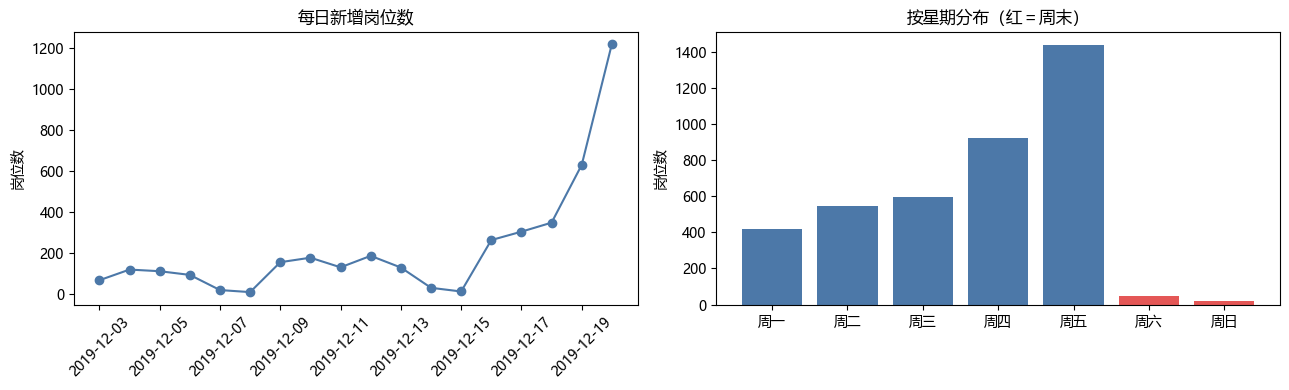

工作日日均 280 条 / 周末日均 16 条（相差 17.0 倍）


In [31]:
# ---- 12.1 每日发布量与星期分布 ----
daily = df.groupby('发布日').size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(daily.index, daily.values, marker='o', color='#4C78A8')
axes[0].set_title('每日新增岗位数')
axes[0].set_ylabel('岗位数')
axes[0].tick_params(axis='x', rotation=45)

wd = df['星期'].value_counts().reindex(['周一', '周二', '周三', '周四', '周五', '周六', '周日'])
axes[1].bar(wd.index, wd.values, color=['#4C78A8'] * 5 + ['#E45756'] * 2)
axes[1].set_title('按星期分布（红＝周末）')
axes[1].set_ylabel('岗位数')

plt.tight_layout()
plt.show()

is_weekend = daily.index.map(lambda d: d.weekday() >= 5)
print(f'工作日日均 {daily[~is_weekend].mean():.0f} 条 / 周末日均 {daily[is_weekend].mean():.0f} 条'
      f'（相差 {daily[~is_weekend].mean() / daily[is_weekend].mean():.1f} 倍）')

**这里有个值得写进报告的发现**：周末发布量骤降——HR 周末不上班。
这既是**数据真实性的旁证**（人工合成的数据不会出现周末周期），
也说明样本跨越了多个工作日，不是单日横截面。

In [32]:
# ---- 12.2 行业集中度（用清洗后的行业字段，而非被污染的原字段）----
ind = (df[df['行业_清洗'] != '未知']
       .groupby('行业_清洗', observed=True)['月薪中位']
       .agg(['size', 'median'])
       .sort_values('size', ascending=False)
       .head(12))
ind.columns = ['岗位数', '薪资中位数']
ind['占比%'] = (ind['岗位数'] / len(df) * 100).round(1)

print('招聘量 TOP12 行业（已剥离融资阶段）：')
print(ind.round(0).to_string())

招聘量 TOP12 行业（已剥离融资阶段）：
                          岗位数  薪资中位数  占比%
行业_清洗                                          
互联网电商                   380     15000.0   10.0
互联网移动互联网电子商务     312     35000.0    8.0
其他                         186     19000.0    5.0
计算机软件                   128     14000.0    3.0
服装纺织                      98      7000.0    2.0
基金证券投资                  96     12500.0    2.0
专业服务                      89     20000.0    2.0
快消品                        83     10000.0    2.0
银行                          79     21500.0    2.0
电子商务                      70     15750.0    2.0
保险                          59     12500.0    2.0
批发零售                      57     10000.0    1.0


In [33]:
# ---- 12.3 福利标签：哪些福利是行业标配 ----
tags = Counter()
for s in df['其他方面'].fillna(''):
    for t in str(s).split('|'):
        if t.strip():
            tags[t.strip()] += 1

top_tags = pd.DataFrame(tags.most_common(12), columns=['福利标签', '出现次数'])
top_tags['覆盖率%'] = (top_tags['出现次数'] / len(df) * 100).round(1)
print(top_tags.to_string(index=False))

  福利标签  出现次数  覆盖率%
  五险一金      1743     43.8
  带薪年假      1624     40.8
发展空间大      1369     34.4
  绩效奖金      1073     26.9
  定期体检      1063     26.7
  岗位晋升      1054     26.5
    领导好       910     22.8
  节日礼物       817     20.5
  午餐补助       753     18.9
  技能培训       749     18.8
  弹性工作       635     15.9
  扁平管理       608     15.3


**业务含义**：福利标签反映企业的软性竞争力。五险一金、带薪年假的覆盖率可以直接当投递筛选条件，
也能反过来验证 JD 里的承诺是不是行业标配（如果不是标配，说明它是这家公司的差异化卖点）。

## 十三、结论汇总（自动生成）

把前面的数字自动拼成结论句，方便直接抄进报告。**每句都带样本量**，这是可信度的底线。

In [34]:
d = df[df['薪资分析可用']]
med = d['月薪中位'].median()
lines = [
    f'1. 样本与口径：{len(df)} 条岗位，其中 {len(d)} 条薪资可统计（{len(d)/len(df)*100:.1f}%），'
    f'其余为面议/异常值，不计入薪资结论。',
    f'2. 整体水平：月薪中位数 {med:,.0f} 元，P25 {d["月薪中位"].quantile(.25):,.0f} / '
    f'P75 {d["月薪中位"].quantile(.75):,.0f} 元；均值 {d["月薪中位"].mean():,.0f} 元高于中位数，分布右偏。',
]

et = group_salary(df, '学历_规范')
if '大专' in et.index and '本科' in et.index:
    lines.append(
        f'3. 学历门槛：大专岗中位数 {et.loc["大专","中位数"]:,.0f} 元（n={int(et.loc["大专","样本量"])}），'
        f'本科 {et.loc["本科","中位数"]:,.0f} 元（n={int(et.loc["本科","样本量"])}），'
        f'相差 {(et.loc["大专","中位数"]/et.loc["本科","中位数"]-1)*100:.0f}%；'
        f'固定岗位方向与职级后差距收窄至 {c:+.1f}%，说明部分差距来自岗位结构，但学历门槛依然存在。')

xt = group_salary(df, '经验档位')
if '1-3年' in xt.index and '3-5年' in xt.index:
    lines.append(
        f'4. 经验溢价：1-3 年 {xt.loc["1-3年","中位数"]:,.0f} 元 → 3-5 年 '
        f'{xt.loc["3-5年","中位数"]:,.0f} 元（+{(xt.loc["3-5年","中位数"]/xt.loc["1-3年","中位数"]-1)*100:.0f}%），'
        f'是薪资增长最快的阶段。')

ct = group_salary(df, '城市')
ct = ct[(ct['样本量'] >= 30) & (ct.index != '未知')].head(3)
lines.append('5. 城市差异：' + '、'.join(
    f'{i} {r["中位数"]:,.0f} 元(n={int(r["样本量"])})' for i, r in ct.iterrows()) + '。')

lines.append(
    f'6. 数据说明：2019-12 猎聘抓取快照；周末日均发布量仅为工作日的 1/'
    f'{daily[~is_weekend].mean()/daily[is_weekend].mean():.0f}，佐证为真实抓取而非模拟数据。')

print('\n'.join(lines))

1. 样本与口径：3984 条岗位，其中 3334 条薪资可统计（83.7%），其余为面议/异常值，不计入薪资结论。
2. 整体水平：月薪中位数 18,500 元，P25 11,500 / P75 30,000 元；均值 21,798 元高于中位数，分布右偏。
3. 学历门槛：大专岗中位数 9,000 元（n=366），本科 20,000 元（n=2601），相差 -55%；固定岗位方向与职级后差距收窄至 -42.9%，说明部分差距来自岗位结构，但学历门槛依然存在。
4. 经验溢价：1-3 年 18,000 元 → 3-5 年 30,000 元（+67%），是薪资增长最快的阶段。
5. 城市差异：北京 22,500 元(n=516)、深圳 20,000 元(n=305)、杭州 20,000 元(n=231)。
6. 数据说明：2019-12 猎聘抓取快照；周末日均发布量仅为工作日的 1/17，佐证为真实抓取而非模拟数据。


---
## 十四、下一步

清洗后的宽表已导出（`数据分析岗_清洗后.csv`），可以继续做：

1. **导入 MySQL** → `dwd` 明细表 + `ads` 指标表，用窗口函数重算分组排名与同环比
2. **BI 看板** → 把上面五张分组表做成可交互图表（Tableau / Power BI / ECharts）
3. **报告成文** → 结论 + 图 + 口径说明，附局限（2019 年数据、单一平台、无 JD 文本）

**简历可直接引用的三个数字**：样本 4,002 条 → 去重 3,984 条；
薪资可统计 3,334 条（83.7%）；学历差距在控制变量后的收窄幅度。